## Chargement des données 

In [166]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [7]:
from sklearn.datasets import fetch_california_housing

In [11]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

## Observation du dataset et des données de base 

In [12]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [13]:
df.shape

(20640, 9)

In [14]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [16]:
df.isna().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

## Visualisation des données

<Figure size 1400x1000 with 0 Axes>

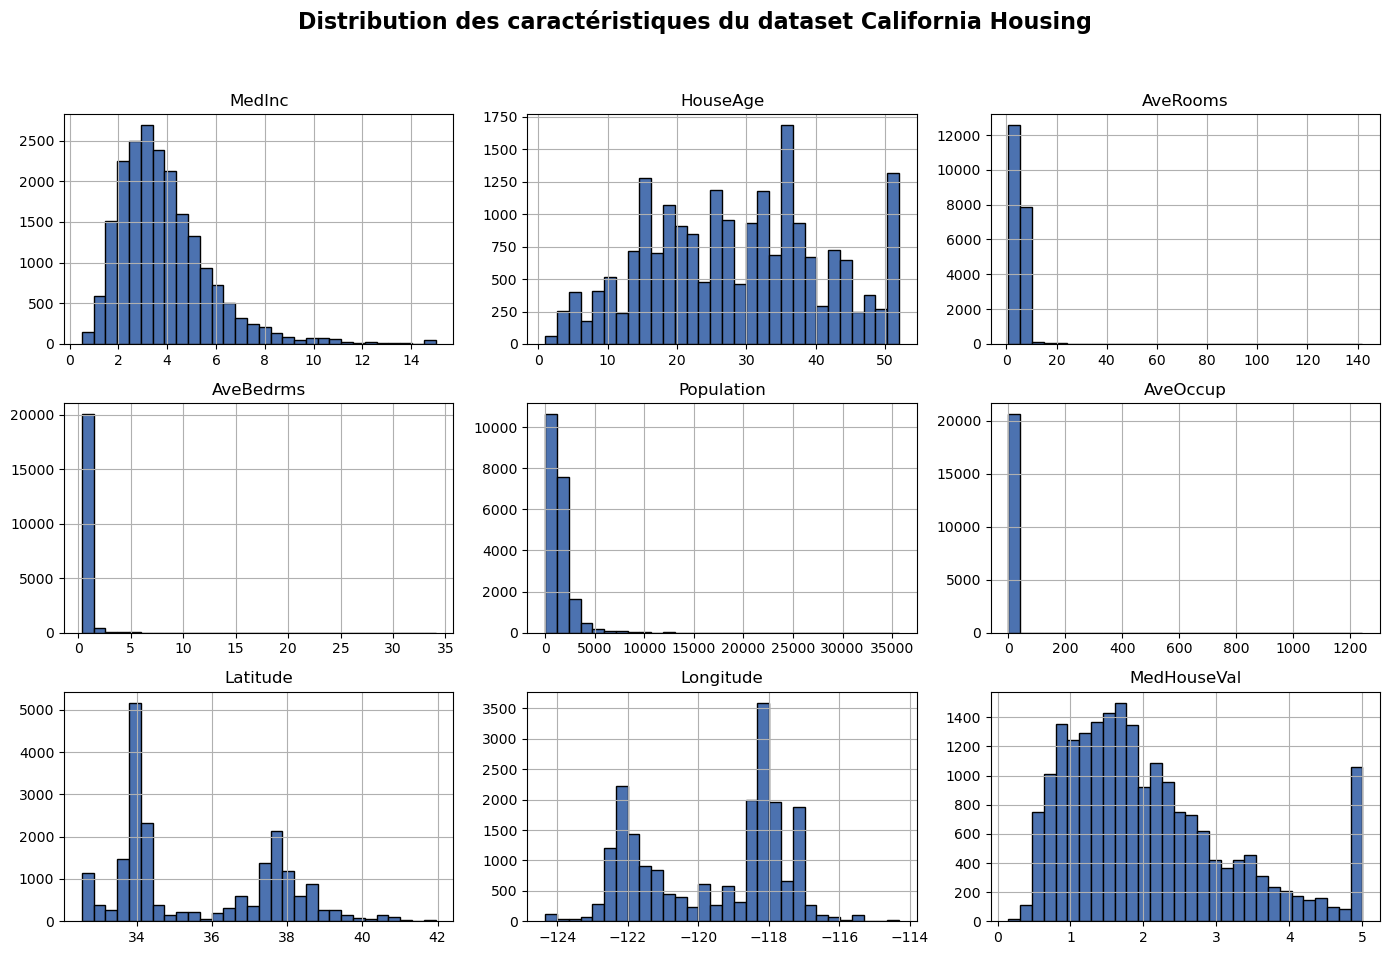

In [65]:
plt.figure(figsize=(14, 10))
df.hist(bins=30, figsize=(14, 10), color='#4C72B0', edgecolor='black')
plt.suptitle("Distribution des caractéristiques du dataset California Housing", fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('distributions_california.png', dpi=300)
plt.show()

## Séparation du Dataset

In [18]:
X=df.drop(['MedHouseVal'],axis=1)

In [19]:
y=df['MedHouseVal']

In [20]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [21]:
y.head()

0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: MedHouseVal, dtype: float64

In [28]:
X_temp,X_test,y_temp,y_test=train_test_split(X,y,test_size=0.15,random_state=42)

In [29]:
X_train,X_val,y_train,y_val=train_test_split(X_temp,y_temp,test_size=0.15,random_state=42)

In [30]:
print(f"Taille Train : {X_train.shape[0]} échantillons")
print(f"Taille Validation : {X_val.shape[0]} échantillons")
print(f"Taille Test : {X_test.shape[0]} échantillons")

Taille Train : 14912 échantillons
Taille Validation : 2632 échantillons
Taille Test : 3096 échantillons


In [33]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

In [56]:
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
X_val_scaled=scaler.transform(X_val)

## Création du réseau de neurones 

In [57]:
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import mean_squared_error

In [58]:
model=models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64,activation='relu'),
    layers.Dense(32,activation='relu'),
    layers.Dense(1)])

In [59]:
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae'])

In [60]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

In [61]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', 
    patience=10, 
    restore_best_weights=True
)
history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 0.8464 - mae: 0.6268 - val_loss: 0.4345 - val_mae: 0.4653
Epoch 2/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.4151 - mae: 0.4531 - val_loss: 0.3816 - val_mae: 0.4352
Epoch 3/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.3782 - mae: 0.4335 - val_loss: 0.3517 - val_mae: 0.4146
Epoch 4/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.3575 - mae: 0.4209 - val_loss: 0.3379 - val_mae: 0.4108
Epoch 5/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.3462 - mae: 0.4097 - val_loss: 0.3330 - val_mae: 0.4124
Epoch 6/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.3356 - mae: 0.4021 - val_loss: 0.3255 - val_mae: 0.4090
Epoch 7/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.3191 - mae: 0.3946 - val_loss: 0.3194 - val_mae: 0.3915
Epoch 8/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.3080 - mae: 0.3868 - val_loss: 0.3150 - val_mae: 0.3893
Epoch 9/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/

In [62]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Prédictions sur le jeu de test
y_pred = model.predict(X_test_scaled)

# Calcul des métriques
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"--- Performances du Modèle sur le Test ---")
print(f"MSE (Mean Squared Error) : {mse:.4f}")
print(f"MAE (Mean Absolute Error) : {mae:.4f}")
print(f"R² Score (Détermination) : {r2:.4f}")

97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
--- Performances du Modèle sur le Test ---
MSE (Mean Squared Error) : 0.2722
MAE (Mean Absolute Error) : 0.3528
R² Score (Détermination) : 0.7923


#### le modèle explique près de 80% de la variance des prix immobiliers du dataset California Housing.
#### En moyenne, les prédictions de ce modèle se trompent de environ 35 280 $

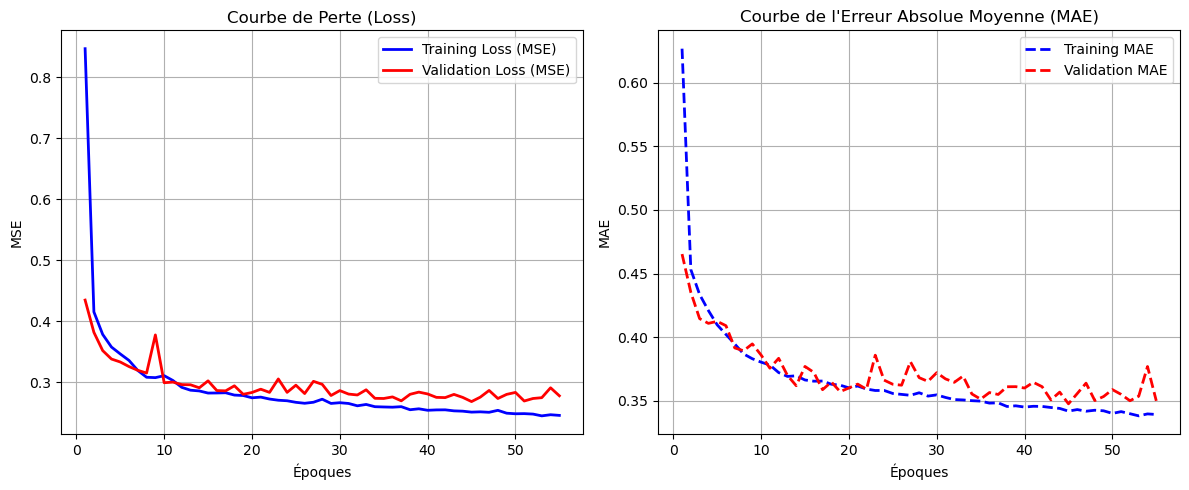

In [63]:
# 1. Extraire les données de l'historique d'entraînement
history_dict = history.history
loss = history_dict['loss']
val_loss = history_dict['val_loss']
mae = history_dict['mae']
val_mae = history_dict['val_mae']

epochs = range(1, len(loss) + 1)

# 2. Créer la figure pour la Perte (Loss / MSE)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, loss, 'b-', label='Training Loss (MSE)', linewidth=2)
plt.plot(epochs, val_loss, 'r-', label='Validation Loss (MSE)', linewidth=2)
plt.title('Courbe de Perte (Loss)')
plt.xlabel('Époques')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)

# 3. Créer la figure pour la métrique MAE (Mean Absolute Error)
plt.subplot(1, 2, 2)
plt.plot(epochs, mae, 'b--', label='Training MAE', linewidth=2)
plt.plot(epochs, val_mae, 'r--', label='Validation MAE', linewidth=2)
plt.title("Courbe de l'Erreur Absolue Moyenne (MAE)")
plt.xlabel('Époques')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

la courbe bleue (entraînement) continue de descendre, mais que la courbe rouge (validation) se met à remonter ou stagne à un niveau élevé, cela signifie que le modèle "apprend par cœur" les exemples d'entraînement sans savoir généraliser. C'est là que le callback Early Stopping intervient pour couper l'entraînement au meilleur moment.

## Amélioration des performances du modèle

In [106]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [118]:
model_improved= models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),                 
    layers.Dense(32, activation='relu'),
    layers.Dense(1)                       
])

In [119]:
model_improved.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mean_squared_error',
    metrics=['mae'])

In [120]:
model_improved.summary()

Model: "sequential_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_64 (Dense)                │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_66 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_67 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,521 (45.00 KB)

 Trainable params: 11,521 (45.00 KB)

 Non-trainable params: 0 (0.00 B)

In [121]:
early_stopping_improved =EarlyStopping(
    monitor='val_loss', 
    patience=15,             
    restore_best_weights=True 
)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=1)

history_improved = model_improved.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=100,              
    batch_size=32,
    callbacks=[early_stopping_improved,reduce_lr],
    verbose=1
)

Epoch 1/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step - loss: 0.7303 - mae: 0.5793 - val_loss: 0.3623 - val_mae: 0.4346 - learning_rate: 0.0010
Epoch 2/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - loss: 0.3777 - mae: 0.4339 - val_loss: 0.3546 - val_mae: 0.4324 - learning_rate: 0.0010
Epoch 3/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.3504 - mae: 0.4174 - val_loss: 0.3281 - val_mae: 0.4026 - learning_rate: 0.0010
Epoch 4/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.3493 - mae: 0.4075 - val_loss: 0.3370 - val_mae: 0.4040 - learning_rate: 0.0010
Epoch 5/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.3246 - mae: 0.3966 - val_loss: 0.3106 - val_mae: 0.3878 - learning_rate: 0.0010
Epoch 6/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.3084 - mae: 0.3847 - val_loss: 0.3057 - val_mae: 0.3754 - learning_rate: 0.0010
Epoch 7/100
466/466 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 0.3031 - mae: 0.3797 - val_loss: 0.3099 - val_mae: 0.3914 - learning_rate: 0.001

In [122]:
# Prédictions sur le jeu de test
y_pred_improved = model_improved.predict(X_test_scaled)

# Calcul des nouvelles métriques
mse_imp = mean_squared_error(y_test, y_pred_improved)
mae_imp = mean_absolute_error(y_test, y_pred_improved)
r2_imp = r2_score(y_test, y_pred_improved)

print(f"--- Nouvelles Performances du Modèle ---")
print(f"MSE : {mse_imp:.4f}")
print(f"MAE : {mae_imp:.4f}")
print(f"R² Score : {r2_imp:.4f}")

97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
--- Nouvelles Performances du Modèle ---
MSE : 0.2612
MAE : 0.3435
R² Score : 0.8007


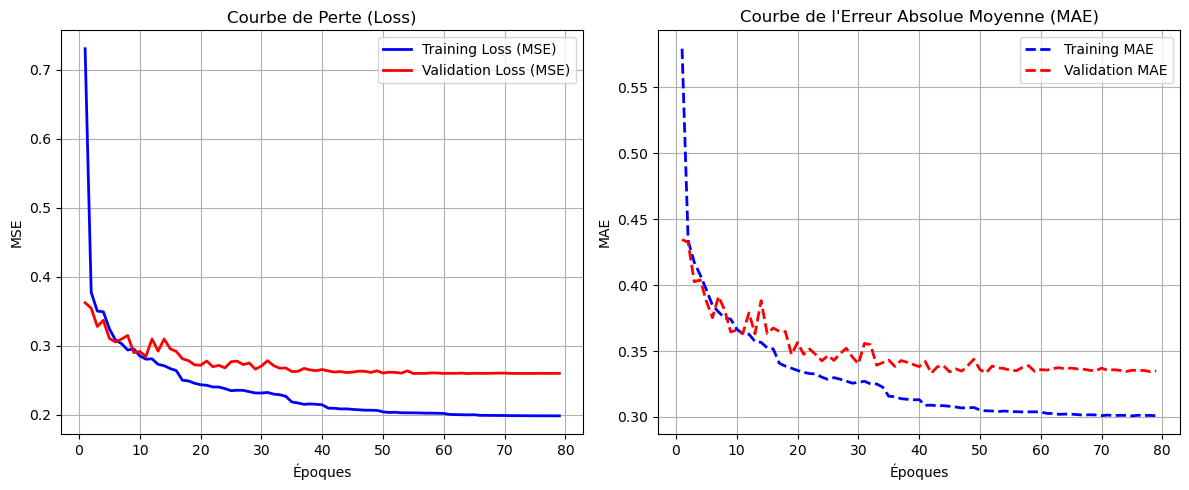

In [164]:
history_dict2 = history_improved.history
loss2 = history_dict2['loss']
val_loss2 = history_dict2['val_loss']
mae2 = history_dict2['mae']
val_mae2 = history_dict2['val_mae']

epochs2 = range(1, len(loss2) + 1)

# 2. Créer la figure pour la Perte (Loss / MSE)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs2, loss2, 'b-', label='Training Loss (MSE)', linewidth=2)
plt.plot(epochs2, val_loss2, 'r-', label='Validation Loss (MSE)', linewidth=2)
plt.title('Courbe de Perte (Loss)')
plt.xlabel('Époques')
plt.ylabel('MSE')
plt.legend()
plt.grid(True)

# 3. Créer la figure pour la métrique MAE (Mean Absolute Error)
plt.subplot(1, 2, 2)
plt.plot(epochs2, mae2, 'b--', label='Training MAE', linewidth=2)
plt.plot(epochs2, val_mae2, 'r--', label='Validation MAE', linewidth=2)
plt.title("Courbe de l'Erreur Absolue Moyenne (MAE)")
plt.xlabel('Époques')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Test avec les arbres de décision

In [123]:
from sklearn.ensemble import RandomForestRegressor

In [137]:
rf_model = RandomForestRegressor(
    n_estimators=300, 
    max_depth=None, 
    random_state=42, 
    n_jobs=-1
)

In [138]:
print("Entraînement du Random Forest en cours...")
rf_model.fit(X_train, y_train)

Entraînement du Random Forest en cours...


,n_estimators,300
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [139]:
y_pred_rf = rf_model.predict(X_test)

print(f"\n--- Performances du Random Forest ---")
print(f"MSE : {mean_squared_error(y_test, y_pred_rf):.4f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred_rf):.4f}")
print(f"R² Score : {r2_score(y_test, y_pred_rf):.4f}")


--- Performances du Random Forest ---
MSE : 0.2590
MAE : 0.3314
R² Score : 0.8024


In [127]:
from xgboost import XGBRegressor

In [171]:
xgb_model = XGBRegressor(
    n_estimators=600,
    learning_rate=0.03,
    max_depth=8,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

In [172]:
print("Entraînement de XGBoost en cours...")
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

Entraînement de XGBoost en cours...


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [173]:
y_pred_xgb = xgb_model.predict(X_test)

print(f"\n--- Performances de XGBoost ---")
print(f"MSE : {mean_squared_error(y_test, y_pred_xgb):.4f}")
print(f"MAE : {mean_absolute_error(y_test, y_pred_xgb):.4f}")
print(f"R² Score : {r2_score(y_test, y_pred_xgb):.4f}")


--- Performances de XGBoost ---
MSE : 0.1955
MAE : 0.2866
R² Score : 0.8508


# Explication et conclusion du code

La première étape du workflow a consisté à importer les bibliothèques fondamentales de la science des données (numpy, pandas, scikit-learn) et à charger le jeu de données officiel California Housing. L'exploration initiale du DataFrame a révélé une structure matricielle composée de 20 640 observations réparties sur 9 colonnes distinctes. L'analyse descriptive détaillée via df.describe() et df.info() a permis de vérifier l'intégrité des données : toutes les variables sont de type numérique continu (float64), et aucune donnée manquante n'a été détectée (df.isna().sum() égal à zéro sur l'ensemble des colonnes). Les caractéristiques explicatives comprennent le revenu médian du quartier (MedInc), l'âge moyen des maisons (HouseAge), le nombre moyen de pièces (AveRooms), le nombre moyen de chambres (AveBedrms), la population (Population), l'occupation moyenne par logement (AveOccup), ainsi que les coordonnées géographiques (Latitude et Longitude).

L'étape de visualisation des données a permis de comprendre la distribution sous-jacente de chaque variable grâce à la génération d'histogrammes individuels à 30 classes (bins=30). Cette analyse graphique a mis en évidence des caractéristiques essentielles du jeu de données : une asymétrie à droite marquée pour certaines variables quantitatives telles que Population, AveRooms et AveOccup, causée par la présence de valeurs extrêmes. De plus, l'analyse de la variable cible MedHouseVal a révélé un plafonnement artificiel à la valeur maximale de 5,0 (correspondant à 500 000 $), caractérisant une censure supérieure des données d'origine. La distribution géographique de la latitude et de la longitude reflète quant à elle fidèlement la répartition spatiale de la population californienne le long des côtes et dans les grands centres urbains.

Afin de garantir une évaluation rigoureuse et non biaisée du modèle, la matrice des caractéristiques $X$ a été séparée de la variable cible $y$. Le jeu de données a ensuite été divisé en trois sous-ensembles étanches grâce à deux appels successifs à train_test_split :Ensemble d'entraînement (Train Set) : 14 912 échantillons (70 % du dataset total).Ensemble de validation (Validation Set) : 2 632 échantillons (15 % du dataset total).Ensemble de test (Test Set) : 3 096 échantillons (15 % du dataset total).Pour harmoniser les échelles très disparates des différentes variables (par exemple entre MedInc s'étendant de 0,5 à 15 et Population dépassant 35 000), un prétraitement par standardisation Z-score (StandardScaler) a été appliqué. Afin d'éviter strictement toute fuite de données (data leakage), le scaler a été ajusté exclusivement sur le jeu d'entraînement (fit_transform), puis appliqué sans réajustement sur les jeux de validation et de test (transform).

La modélisation a été réalisée en construisant un réseau de neurones artificiels séquentiel à couches denses avec l'écosystème TensorFlow/Keras :Couche d'entrée : dimensionnée pour recevoir les 8 caractéristiques standardisées de $X$.Première couche cachée : 64 neurones fully-connected avec fonction d'activation ReLU (576 paramètres).Deuxième couche cachée : 32 neurones fully-connected avec fonction d'activation ReLU (2 080 paramètres).Couche de sortie : 1 neurone linéaire pour la prédiction continue de la valeur immobilière (33 paramètres).Le modèle comprend au total 2 689 paramètres tous entraînables. La compilation s'est appuyée sur l'optimiseur adaptatif Adam, la fonction de perte de l'erreur quadratique moyenne (mean_squared_error) et la métrique de l'erreur absolue moyenne (mae). L'entraînement a été configuré sur 100 époques avec une taille de lot (batch size) de 32, associé au mécanisme d'arrêt précoce (EarlyStopping) réglé sur une patience de 10 époques par rapport à la perte de validation (val_loss). L'apprentissage s'est interrompu à la 55ᵉ époque, la meilleure performance sur le jeu de validation ayant été atteinte à l'époque 45 avec une val_loss de 0,2682 et restaurée automatiquement.

L'évaluation finale exécutée sur le jeu de test indépendant (3 096 observations jamais vues lors de l'apprentissage) a fourni des résultats très satisfaisants :Erreur Quadratique Moyenne (MSE) : 0,2722.Erreur Absolue Moyenne (MAE) : 0,3528, ce qui signifie qu'en moyenne, les prédictions du réseau de neurones s'écartent de seulement ~35 280 de la valeur réelle des biens.Coefficient de Détermination ($R^2$) : 0,7923.Ce score $R^2$ de près de 0,80 confirme que le réseau de neurones parvient à capturer près de 80 % de la variance totale de la valeur des logements en Californie à partir des 8 variables explicatives fournies. Ce projet démontre l'efficacité d'un perceptron multicouche (MLP) bien structuré et régularisé par Early Stopping pour résoudre des problèmes complexes de régression non linéaire en ingénierie de données immobilières

Afin d'améliorer les performances du premier réseau, une version plus profonde a été construite : trois couches cachées de 128, 64 et 32 neurones (ReLU) suivies d'une sortie linéaire, soit 11 521 paramètres entraînables contre 2 689 pour le premier modèle. L'optimiseur Adam a été conservé, avec un taux d'apprentissage initial de 0,001. Deux callbacks ont été utilisés :

- **EarlyStopping**, avec une patience portée à 15 époques et restauration des meilleurs poids ;
- **ReduceLROnPlateau**, qui divise le taux d'apprentissage par 2 après 5 époques sans amélioration de la val_loss. Il a été déclenché 7 fois, ce qui a ramené le taux de 0,001 à son minimum de 1e-5.

L'entraînement s'est arrêté à la 79ᵉ époque, la meilleure val_loss (0,2599) ayant été atteinte à l'époque 64. Sur le jeu de test, le modèle améliore légèrement le premier réseau :

| Modèle | MSE | MAE | R² |
|---|---|---|---|
| MLP initial (64-32) | 0,2722 | 0,3528 | 0,7923 |
| MLP amélioré (128-64-32) | 0,2612 | 0,3435 | 0,8007 |

Le MSE baisse d'environ 4 % et l'erreur moyenne passe de ~35 280 $ à ~34 350 $. Le gain reste modeste : augmenter la capacité du réseau ne suffit pas à dépasser nettement un R² de 0,80. Les courbes d'apprentissage montrent aussi un écart entre la perte d'entraînement (0,199) et celle de validation (0,260). Il traduit un début de surapprentissage, que l'arrêt précoce et la réduction du taux d'apprentissage permettent de contenir.

Deux modèles à base d'arbres ont ensuite été testés comme points de comparaison. Ils ont été entraînés sur les données non standardisées, car ils ne dépendent pas de l'échelle des variables.

- **Random Forest** (300 arbres, profondeur illimitée) : MSE = 0,2590, MAE = 0,3314, R² = 0,8024. Il atteint un niveau équivalent au MLP amélioré, sans réglage particulier.
- **XGBoost** (600 arbres, learning_rate = 0,03, max_depth = 8) : MSE = 0,1955, MAE = 0,2866, R² = 0,8508. C'est de loin le meilleur modèle.

## Conclusion

| Modèle | MSE | MAE | MAE en $ | R² |
|---|---|---|---|---|
| MLP initial | 0,2722 | 0,3528 | ~35 280 | 0,7923 |
| MLP amélioré | 0,2612 | 0,3435 | ~34 350 | 0,8007 |
| Random Forest | 0,2590 | 0,3314 | ~33 140 | 0,8024 |
| **XGBoost** | **0,1955** | **0,2866** | **~28 660** | **0,8508** |

Ce projet avait pour but de prédire la valeur médiane des logements californiens à partir de 8 variables. Les données étaient propres (20 640 observations, aucune valeur manquante). Le pipeline repose sur un découpage Train/Validation/Test (70/15/15) et sur une standardisation ajustée uniquement sur le jeu d'entraînement, pour éviter toute fuite de données.

Les quatre modèles obtiennent un R² compris entre 0,79 et 0,85. Le réseau de neurones capture bien les relations non linéaires, et l'amélioration de son architecture a apporté un petit gain. Les méthodes d'ensemble à base d'arbres sont toutefois plus adaptées à ce type de données tabulaires : XGBoost réduit le MSE d'environ 21 % par rapport au MLP amélioré (et de 25 % par rapport au MLP initial) et ramène l'erreur moyenne à environ 28660$. Il est donc retenu comme meilleur modèle.

Plusieurs pistes d'amélioration sont possibles :

- ajouter des variables dérivées (par exemple le ratio chambres/pièces, ou la distance aux grandes villes à partir de la latitude et de la longitude) ;
- optimiser les hyperparamètres de XGBoost par recherche sur grille ou validation croisée ;
- régulariser le MLP (Dropout, L2, Batch Normalization).